## Seasonal drought index (CDI)

In [ ]:
# =============================================================================
# SEASONAL CDI DROUGHT CATEGORIES (2030-2050): SSP2-4.5 AND SSP5-8.5
# WITH THE TEKEZE BASIN BOUNDARY OVERLAID
# =============================================================================
# Reads the six seasonal average CDI tifs, classifies each pixel and draws one
# figure: rows = scenarios, columns = seasons (Belg, Kiremt, Bega).
#
# CATEGORIES:
#   No drought (> -0.5) | Mild (-0.5 to -1.0) | Moderate (-1.0 to -1.5)
#   Severe (-1.5 to -2) | Extreme (<= -2)
#
# INPUT : NEX-GDDP-CMIP6\CDI_future_final\Seasonal_tif\CDI_{scenario}_{season}_mean.tif
#         Tekeze boundary shapefile (SHP_PATH)
# OUTPUT: same folder
#           CDI_seasonal_categories_ssp245_ssp585.png
#           CDI_seasonal_category_area.csv  (% of basin area per category)
# =============================================================================

import os
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show

FOLDER   = r"C:\Users\gerii\Documents\projects\tekeze\NEX-GDDP-CMIP6\CDI_future_final\Seasonal_tif"
SHP_PATH = r"C:\Users\geri geri\Desktop\study_area\tekeze\tekeze.shp"
OUT_PNG  = os.path.join(FOLDER, "CDI_seasonal_categories_ssp245_ssp585.png")
OUT_CSV  = os.path.join(FOLDER, "CDI_seasonal_category_area.csv")

BOUNDARY_COLOR = "black"
BOUNDARY_WIDTH = 1.6

SCENARIOS = [("ssp245", "SSP2-4.5"), ("ssp585", "SSP5-8.5")]
SEASONS   = [("Belg", "Belg (Feb-May)"), ("Kiremt", "Kiremt (Jun-Sep)"),
             ("Bega", "Bega (Oct-Jan)")]

NAMES = ["No drought (> -0.5)", "Mild drought (-0.5 to -1.0)",
         "Moderate drought (-1.0 to -1.5)", "Severe drought (-1.5 to -2)",
         "Extreme drought (≤ -2)"]
SHORT  = ["No drought", "Mild", "Moderate", "Severe", "Extreme"]
COLORS = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]

cmap = ListedColormap(COLORS)
norm = BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

def classify(a):
    c = np.full(a.shape, np.nan)
    v = np.isfinite(a)
    c[v & (a > -0.5)] = 0
    c[v & (a <= -0.5) & (a > -1.0)] = 1
    c[v & (a <= -1.0) & (a > -1.5)] = 2
    c[v & (a <= -1.5) & (a > -2.0)] = 3
    c[v & (a <= -2.0)] = 4
    return c

def read(path):
    with rasterio.open(path) as s:
        a = s.read(1).astype("float32")
        if s.nodata is not None and not np.isnan(s.nodata):
            a[a == s.nodata] = np.nan
        tr, crs, b = s.transform, s.crs, s.bounds
    a[a <= -9000] = np.nan
    return a, tr, crs, b

# ---- boundary, reprojected to the raster CRS
if not os.path.exists(SHP_PATH):
    raise SystemExit(f"Shapefile not found: {SHP_PATH}")
first = os.path.join(FOLDER, f"CDI_{SCENARIOS[0][0]}_{SEASONS[0][0]}_mean.tif")
_, _, raster_crs, _ = read(first)
shp = gpd.read_file(SHP_PATH)
if shp.crs is not None and raster_crs is not None and shp.crs != raster_crs:
    shp = shp.to_crs(raster_crs)

plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.2})

fig, axes = plt.subplots(2, 3, figsize=(18, 13))
fig.subplots_adjust(left=0.07, right=0.98, top=0.93, bottom=0.14,
                    wspace=0.04, hspace=0.12)

rows, n = [], 0
for i, (sc, sc_label) in enumerate(SCENARIOS):
    for j, (se, se_label) in enumerate(SEASONS):
        ax = axes[i, j]
        path = os.path.join(FOLDER, f"CDI_{sc}_{se}_mean.tif")
        if not os.path.exists(path):
            raise SystemExit(f"Missing file: {path}")
        a, tr, crs, b = read(path)
        cls = classify(a)
        show(cls, ax=ax, cmap=cmap, norm=norm, transform=tr)

        # boundary on top of the map, axes kept at the raster extent
        shp.boundary.plot(ax=ax, color=BOUNDARY_COLOR, linewidth=BOUNDARY_WIDTH, zorder=5)
        ax.set_xlim(b.left, b.right)
        ax.set_ylim(b.bottom, b.top)

        nn = np.sum(np.isfinite(cls))
        pct = [100 * float(np.sum(cls == k)) / nn for k in range(5)]
        rows.append([sc_label, se, round(float(np.nanmean(a)), 3)] + [round(p, 1) for p in pct])

        txt = "\n".join(f"{SHORT[k]}: {pct[k]:.0f}%" for k in range(5) if pct[k] >= 0.5)
        ax.text(0.03, 0.03, txt, transform=ax.transAxes, fontsize=15, va="bottom",
                bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                          edgecolor="grey", alpha=0.9), zorder=10)

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title("")
        if i == 0:
            ax.text(0.5, 1.12, se_label, transform=ax.transAxes, fontsize=22,
                    fontweight="bold", ha="center", va="bottom")
        ax.text(0.5, 1.01, "abcdef"[n], transform=ax.transAxes, fontsize=22,
                fontweight="bold", ha="center", va="bottom")
        n += 1
        if j == 0:
            ax.text(-0.06, 0.5, sc_label, transform=ax.transAxes, fontsize=22,
                    fontweight="bold", rotation=90, ha="center", va="center")

handles = [mpatches.Patch(color=COLORS[k], label=NAMES[k]) for k in range(5)]
handles.append(mpatches.Patch(facecolor="none", edgecolor=BOUNDARY_COLOR,
                              linewidth=BOUNDARY_WIDTH, label="Tekeze basin boundary"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=18)

fig.savefig(OUT_PNG, dpi=500, bbox_inches="tight")
plt.close(fig)

pd.DataFrame(rows, columns=["Scenario", "Season", "Mean CDI"] +
             [f"{s} (%)" for s in SHORT]).to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print(pd.DataFrame(rows, columns=["Scenario", "Season", "Mean CDI"] + SHORT).to_string(index=False))
print("\nSaved:", OUT_PNG)
print("Saved:", OUT_CSV)

## Anuual drought index(CDI)

In [1]:
# =============================================================================
# ANNUAL CDI DROUGHT CATEGORIES FOR 2030, 2035, 2040, 2045, 2050
# SSP2-4.5 AND SSP5-8.5 (10 PANELS) WITH THE TEKEZE BASIN BOUNDARY
# + ANNUAL MEAN CDI TABLE FOR EVERY YEAR 2030-2050
# =============================================================================
# Annual CDI = mean of the 12 monthly projected CDI maps of the year.
#
# CATEGORIES:
#   No drought (> -0.5) | Mild (-0.5 to -1.0) | Moderate (-1.0 to -1.5)
#   Severe (-1.5 to -2) | Extreme (<= -2)
#
# INPUT : NEX-GDDP-CMIP6\CDI_future_final\{scenario}\*_yyyy_mm.tif
#         Tekeze boundary shapefile (SHP_PATH)
# OUTPUT: NEX-GDDP-CMIP6\CDI_future_final\Annual_maps\
#           CDI_annual_5yr.png
#           CDI_annual_mean_and_area.csv        (5 map years: mean CDI, % area per category)
#           CDI_annual_mean_all_years.csv       (every year 2030-2050: mean CDI per scenario)
# =============================================================================

import os, re, glob, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import rasterio
import geopandas as gpd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.plot import show

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"
CDI_DIR  = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "CDI_future_final")
SHP_PATH = r"C:\Users\geri geri\Desktop\study_area\tekeze\tekeze.shp"
OUT_DIR  = os.path.join(CDI_DIR, "Annual_maps")
os.makedirs(OUT_DIR, exist_ok=True)
OUT_PNG  = os.path.join(OUT_DIR, "CDI_annual_5yr.png")
OUT_CSV  = os.path.join(OUT_DIR, "CDI_annual_mean_and_area.csv")
OUT_CSV_ALL = os.path.join(OUT_DIR, "CDI_annual_mean_all_years.csv")

YEARS = [2030, 2035, 2040, 2045, 2050]          # years shown on the map
ALL_YEARS = list(range(2030, 2051))             # years in the annual mean table
SCENARIOS = [("ssp245", "SSP2-4.5"), ("ssp585", "SSP5-8.5")]

BOUNDARY_COLOR, BOUNDARY_WIDTH = "black", 1.6

NAMES = ["No drought (> -0.5)", "Mild drought (-0.5 to -1.0)",
         "Moderate drought (-1.0 to -1.5)", "Severe drought (-1.5 to -2)",
         "Extreme drought (≤ -2)"]
SHORT  = ["No drought", "Mild", "Moderate", "Severe", "Extreme"]
COLORS = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]
cmap = ListedColormap(COLORS)
norm = BoundaryNorm([0, 1, 2, 3, 4, 5], cmap.N)

def classify(a):
    c = np.full(a.shape, np.nan)
    v = np.isfinite(a)
    c[v & (a > -0.5)] = 0
    c[v & (a <= -0.5) & (a > -1.0)] = 1
    c[v & (a <= -1.0) & (a > -1.5)] = 2
    c[v & (a <= -1.5) & (a > -2.0)] = 3
    c[v & (a <= -2.0)] = 4
    return c

def read(p):
    with rasterio.open(p) as s:
        a = s.read(1).astype("float32")
        if s.nodata is not None and not np.isnan(s.nodata):
            a[a == s.nodata] = np.nan
        tr, crs, b = s.transform, s.crs, s.bounds
    a[a <= -9000] = np.nan
    return a, tr, crs, b

pat = re.compile(r"(\d{4})_(\d{2})\.tif$")

# ---- annual mean maps (map years)
annual, tr0, crs0, b0 = {}, None, None, None
for sc, _ in SCENARIOS:
    files = {}
    for f in glob.glob(os.path.join(CDI_DIR, sc, "*.tif")):
        m = pat.search(os.path.basename(f))
        if m:
            files[(int(m.group(1)), int(m.group(2)))] = f
    for y in YEARS:
        paths = [files[(y, m)] for m in range(1, 13) if (y, m) in files]
        if len(paths) < 12:
            print(f"WARNING: {sc} {y} has {len(paths)} months")
        if not paths:
            raise SystemExit(f"No files for {sc} {y}")
        st = []
        for p in paths:
            a, tr, crs, b = read(p)
            st.append(a)
            if tr0 is None:
                tr0, crs0, b0 = tr, crs, b
        annual[(sc, y)] = np.nanmean(st, axis=0).astype("float32")

# ---- annual mean CDI for EVERY year 2030-2050 (table only)
rows_all = []
for sc, sc_label in SCENARIOS:
    fl = {}
    for f in glob.glob(os.path.join(CDI_DIR, sc, "*.tif")):
        m = pat.search(os.path.basename(f))
        if m:
            fl[(int(m.group(1)), int(m.group(2)))] = f
    for y in ALL_YEARS:
        paths = [fl[(y, m)] for m in range(1, 13) if (y, m) in fl]
        if not paths:
            continue
        a = np.nanmean([read(p)[0] for p in paths], axis=0)
        rows_all.append([sc_label, y, len(paths), round(float(np.nanmean(a)), 3)])

T_all = pd.DataFrame(rows_all, columns=["Scenario", "Year", "Months used", "Mean CDI"])
T_wide = T_all.pivot(index="Year", columns="Scenario", values="Mean CDI").reset_index()
T_wide.to_csv(OUT_CSV_ALL, index=False, encoding="utf-8-sig")
print("\nANNUAL MEAN CDI, EVERY YEAR\n", T_wide.to_string(index=False))
if (T_all["Months used"] < 12).any():
    print("\nWARNING: some years have fewer than 12 months:\n",
          T_all[T_all["Months used"] < 12].to_string(index=False))

# ---- boundary
if not os.path.exists(SHP_PATH):
    raise SystemExit(f"Shapefile not found: {SHP_PATH}")
shp = gpd.read_file(SHP_PATH)
if shp.crs is not None and crs0 is not None and shp.crs != crs0:
    shp = shp.to_crs(crs0)

plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.2})
fig, axes = plt.subplots(2, 5, figsize=(28, 12.5))
fig.subplots_adjust(left=0.05, right=0.995, top=0.91, bottom=0.14, wspace=0.04, hspace=0.12)

rows, n = [], 0
for i, (sc, sc_label) in enumerate(SCENARIOS):
    for j, y in enumerate(YEARS):
        ax = axes[i, j]
        a = annual[(sc, y)]
        cls = classify(a)
        show(cls, ax=ax, cmap=cmap, norm=norm, transform=tr0)
        shp.boundary.plot(ax=ax, color=BOUNDARY_COLOR, linewidth=BOUNDARY_WIDTH, zorder=5)
        ax.set_xlim(b0.left, b0.right); ax.set_ylim(b0.bottom, b0.top)

        nn = np.sum(np.isfinite(cls))
        pct = [100 * float(np.sum(cls == k)) / nn for k in range(5)]
        mean_cdi = float(np.nanmean(a))
        rows.append([sc_label, y, round(mean_cdi, 3)] + [round(p, 1) for p in pct])

        # percentages only (mean CDI is kept in the table, not on the map)
        txt = "\n".join(f"{SHORT[k]}: {pct[k]:.0f}%" for k in range(5) if pct[k] >= 0.5)
        ax.text(0.03, 0.03, txt, transform=ax.transAxes, fontsize=20, va="bottom",
                bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                          edgecolor="grey", alpha=0.9), zorder=10)

        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title("")
        if i == 0:
            ax.text(0.5, 1.12, str(y), transform=ax.transAxes, fontsize=22,
                    fontweight="bold", ha="center", va="bottom")
        ax.text(0.5, 1.01, "abcdefghij"[n], transform=ax.transAxes, fontsize=22,
                fontweight="bold", ha="center", va="bottom")
        n += 1
        if j == 0:
            ax.text(-0.06, 0.5, sc_label, transform=ax.transAxes, fontsize=22,
                    fontweight="bold", rotation=90, ha="center", va="center")

handles = [mpatches.Patch(color=COLORS[k], label=NAMES[k]) for k in range(5)]
handles.append(mpatches.Patch(facecolor="none", edgecolor=BOUNDARY_COLOR,
                              linewidth=BOUNDARY_WIDTH, label="Tekeze basin boundary"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=18)

# ---- table first, so the numbers are saved even if the picture fails
T = pd.DataFrame(rows, columns=["Scenario", "Year", "Mean CDI"] + [f"{s} (%)" for s in SHORT])
T.to_csv(OUT_CSV, index=False, encoding="utf-8-sig")
print("\nMAP YEARS: MEAN CDI AND % AREA PER CATEGORY\n", T.to_string(index=False))

# ---- save the picture, with fall-backs if Windows refuses the file
saved = None
attempts = [(OUT_PNG, 450),
            (OUT_PNG, 300),
            (os.path.join(BASE_DIR, "CDI_annual_5yr.png"), 300),
            (os.path.join(os.path.expanduser("~"), "CDI_annual_5yr.png"), 200)]
for path, dpi in attempts:
    try:
        fig.savefig(path, dpi=dpi, bbox_inches="tight")
        saved = path
        break
    except OSError as e:
        print(f"Could not save to {path} at {dpi} dpi: {e}")
plt.close(fig)

if saved:
    print("\nSaved picture:", saved)
else:
    print("\nThe picture could not be saved. Close any program showing the old PNG "
          "and check that the folder is not locked by OneDrive or antivirus.")
print("Saved table  :", OUT_CSV)
print("Saved table  :", OUT_CSV_ALL)


ANNUAL MEAN CDI, EVERY YEAR
  Year  SSP2-4.5  SSP5-8.5
 2030    -0.648    -0.635
 2031    -0.585    -0.574
 2032    -0.590    -0.574
 2033    -0.590    -0.601
 2034    -0.590    -0.580
 2035    -0.569    -0.508
 2036    -0.585    -0.592
 2037    -0.590    -0.558
 2038    -0.600    -0.585
 2039    -0.586    -0.626
 2040    -0.582    -0.590
 2041    -0.540    -0.570
 2042    -0.639    -0.581
 2043    -0.599    -0.580
 2044    -0.573    -0.569
 2045    -0.618    -0.599
 2046    -0.641    -0.583
 2047    -0.596    -0.511
 2048    -0.601    -0.551
 2049    -0.624    -0.555
 2050    -0.574    -0.538


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\gerii\\Documents\\projects\\tekeze\\NEX-GDDP-CMIP6\\CDI_future_final\\Annual_maps\\CDI_annual_mean_and_area.csv'

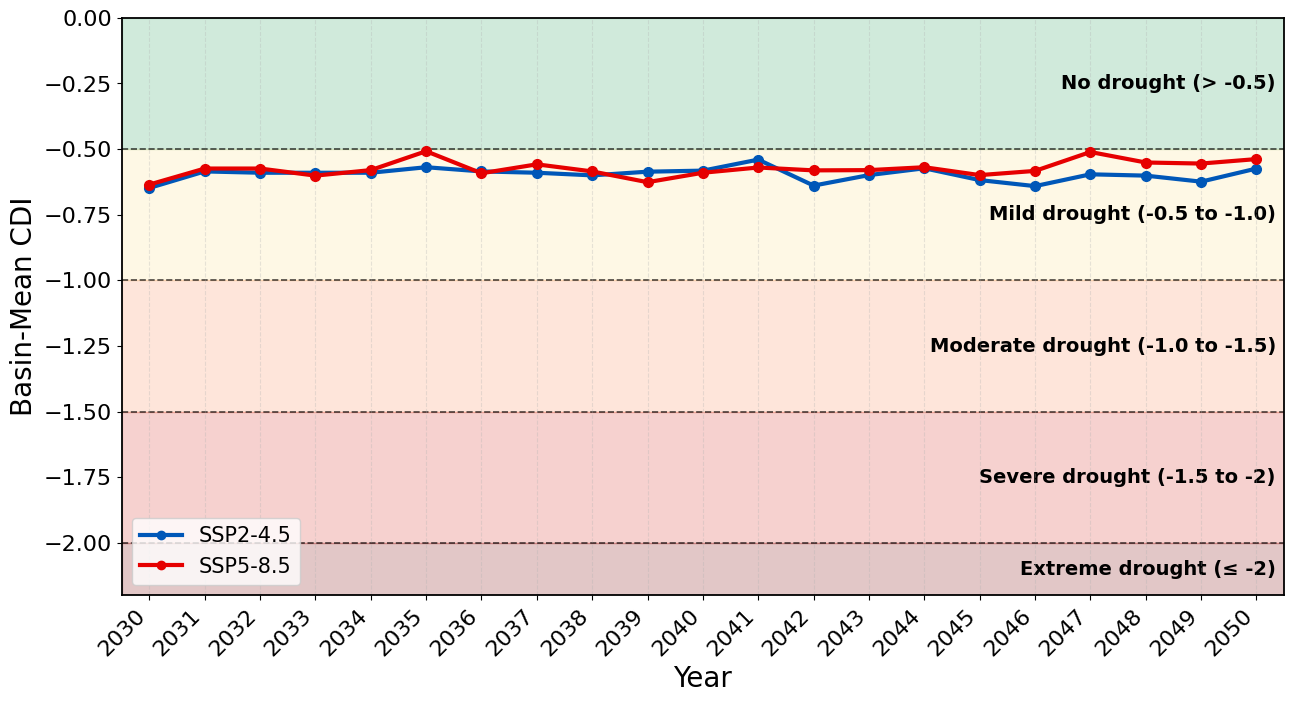

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

years = np.arange(2030, 2051)
ssp245 = np.array([-0.648, -0.585, -0.590, -0.590, -0.590, -0.569, -0.585, -0.590, -0.600, -0.586, -0.582,
                   -0.540, -0.639, -0.599, -0.573, -0.618, -0.641, -0.596, -0.601, -0.624, -0.574])
ssp585 = np.array([-0.635, -0.574, -0.574, -0.601, -0.580, -0.508, -0.592, -0.558, -0.585, -0.626, -0.590,
                   -0.570, -0.581, -0.580, -0.569, -0.599, -0.583, -0.511, -0.551, -0.555, -0.538])

C45, C85 = "#0057b8", "#e60000"        # line colors

# classification, same limits and colors as the map script
BOUNDS = [0.0, -0.5, -1.0, -1.5, -2.0, -2.2]          # lower edge of the plot at -2.2
NAMES  = ["No drought (> -0.5)", "Mild drought (-0.5 to -1.0)",
          "Moderate drought (-1.0 to -1.5)", "Severe drought (-1.5 to -2)",
          "Extreme drought (≤ -2)"]
COLORS = ["#2ca25f", "#fee08b", "#fc8d59", "#d73027", "#7f0000"]

plt.rcParams.update({"font.family": "sans-serif", "font.size": 16, "axes.linewidth": 1.3})
fig, ax = plt.subplots(figsize=(15, 7.5))

# shaded class bands with the class name written inside each band
for k in range(5):
    top, bot = BOUNDS[k], BOUNDS[k + 1]
    ax.axhspan(bot, top, color=COLORS[k], alpha=0.22, zorder=0)
    ax.text(2050.35, (top + bot) / 2, NAMES[k], ha="right", va="center",
            fontsize=14, fontweight="bold", color="black", zorder=1)

# class limits
for b in [-0.5, -1.0, -1.5, -2.0]:
    ax.axhline(b, color="black", lw=1.2, ls="--", alpha=0.7, zorder=1)

# curves
ax.plot(years, ssp245, "-o", color=C45, lw=3, ms=7, zorder=3)
ax.plot(years, ssp585, "-o", color=C85, lw=3, ms=7, zorder=3)

ax.set_xlim(2029.5, 2050.5)
ax.set_ylim(-2.2, 0.0)
ax.set_xticks(years)
ax.set_xticklabels(years, rotation=45, ha="right")
ax.set_xlabel("Year", fontsize=20)
ax.set_ylabel("Basin-Mean CDI", fontsize=20)
ax.grid(True, axis="x", ls="--", alpha=0.3)

handles = [Line2D([0], [0], color=C45, lw=3, marker="o", label="SSP2-4.5"),
           Line2D([0], [0], color=C85, lw=3, marker="o", label="SSP5-8.5")]
ax.legend(handles=handles, loc="lower left", frameon=True, fontsize=15)

fig.savefig("Fig16_CDI_annual_lineplot.png", dpi=400, bbox_inches="tight")
plt.show()

### return period and frequency

In [5]:
# =============================================================================
# DROUGHT FREQUENCY AND RETURN PERIOD FROM FUTURE MONTHLY CDI (2030-2050)
# SSP2-4.5 AND SSP5-8.5
# =============================================================================
#
# Frequency (%)  = share of all pixel-months in the category
# Return period  = 100 / frequency (%), in months
#
# TABLE 1: categories (each pixel-month falls in one category)
#   No drought > -0.5 | Mild -0.5 to -1.0 | Moderate -1.0 to -1.5
#   Severe -1.5 to -2 | Extreme <= -2
# TABLE 2: cumulative thresholds (each includes all more severe pixels)
#   CDI <= -0.5, <= -1.0, <= -1.5, <= -2
#
# SEASON OPTION:
#   MONTHS = list(range(1, 13)) uses all months.
#   Use e.g. MONTHS = [6, 7, 8, 9] for the rainy season only.
#
# INPUT : NEX-GDDP-CMIP6\CDI_future_final\{scenario}\*_yyyy_mm.tif
# OUTPUT: NEX-GDDP-CMIP6\CDI_future_final\Frequency_return_period\
#           CDI_freq_RP_<scenario>_<months>.csv
#           CDI_freq_RP_both_scenarios_<months>.csv
# =============================================================================

import os
import re
import csv
import glob
import numpy as np
import rasterio

START_YEAR, END_YEAR = 2030, 2050
MONTHS = list(range(1, 13))          # e.g. [6, 7, 8, 9] for June-September
SCENARIOS = [("ssp245", "SSP2-4.5"), ("ssp585", "SSP5-8.5")]

BASE_DIR = r"C:\Users\gerii\Documents\projects\tekeze"
CDI_DIR  = os.path.join(BASE_DIR, "NEX-GDDP-CMIP6", "CDI_future_final")
OUT_DIR  = os.path.join(CDI_DIR, "Frequency_return_period")
os.makedirs(OUT_DIR, exist_ok=True)
tag = "all_months" if MONTHS == list(range(1, 13)) else "months_" + "_".join(map(str, MONTHS))

pattern = re.compile(r"(\d{4})_(\d{1,2})\.tif$", re.IGNORECASE)

CATS = [
    ("No drought (> -0.5)",              lambda v: v > -0.5),
    ("Mild drought (-0.5 to -1.0)",      lambda v: (v <= -0.5) & (v > -1.0)),
    ("Moderate drought (-1.0 to -1.5)",  lambda v: (v <= -1.0) & (v > -1.5)),
    ("Severe drought (-1.5 to -2)",      lambda v: (v <= -1.5) & (v > -2.0)),
    ("Extreme drought (≤ -2)",           lambda v: v <= -2.0),
]
CUM = [
    ("Any drought (CDI ≤ -0.5)",         lambda v: v <= -0.5),
    ("Moderate or worse (≤ -1.0)",       lambda v: v <= -1.0),
    ("Severe or worse (≤ -1.5)",         lambda v: v <= -1.5),
    ("Extreme (≤ -2)",                   lambda v: v <= -2.0),
]

def rp(freq):
    return round(100.0 / freq, 2) if freq > 0 else float("inf")

def analyse(folder):
    cnt = np.zeros(len(CATS))
    cum = np.zeros(len(CUM))
    total, n_files = 0, 0
    for f in sorted(glob.glob(os.path.join(folder, "*.tif"))):
        mt = pattern.search(os.path.basename(f))
        if mt is None:
            continue
        y, m = int(mt.group(1)), int(mt.group(2))
        if not (START_YEAR <= y <= END_YEAR and m in MONTHS):
            continue
        with rasterio.open(f) as src:
            a = src.read(1).astype("float32")
            if src.nodata is not None and not np.isnan(src.nodata):
                a[a == src.nodata] = np.nan
        a[a <= -9000] = np.nan
        v = a[np.isfinite(a)]
        total += len(v)
        n_files += 1
        for i, (_, t) in enumerate(CATS):
            cnt[i] += np.sum(t(v))
        for i, (_, t) in enumerate(CUM):
            cum[i] += np.sum(t(v))
    return cnt, cum, total, n_files

results = {}
for sc, label in SCENARIOS:
    folder = os.path.join(CDI_DIR, sc)
    if not os.path.isdir(folder):
        raise SystemExit(f"Folder not found: {folder}")
    cnt, cum, total, n_files = analyse(folder)
    if total == 0:
        raise SystemExit(f"No CDI values found for {label}. Check the folder and MONTHS.")
    results[sc] = (cnt, cum, total, n_files)
    print(f"{label}: {n_files} monthly maps, {total:,} pixel-months, months = {MONTHS}")

# ---- one CSV per scenario
for sc, label in SCENARIOS:
    cnt, cum, total, _ = results[sc]
    rows = []
    for title, items, counts in [("TABLE 1: categories", CATS, cnt),
                                 ("TABLE 2: cumulative thresholds", CUM, cum)]:
        rows.append([title, "", ""])
        for (name, _), c in zip(items, counts):
            fr = round(100 * c / total, 1)
            rows.append([name, fr, rp(fr)])
    out = os.path.join(OUT_DIR, f"CDI_freq_RP_{sc}_{tag}.csv")
    with open(out, "w", newline="", encoding="utf-8-sig") as fh:
        w = csv.writer(fh)
        w.writerow(["Drought category", "Frequency (%)", "Return period (months)"])
        w.writerows(rows)

# ---- both scenarios side by side (print and combined CSV)
comb = [["Drought category",
         "SSP2-4.5 Frequency (%)", "SSP2-4.5 Return period (months)",
         "SSP5-8.5 Frequency (%)", "SSP5-8.5 Return period (months)"]]
for title, items, idx in [("TABLE 1: categories", CATS, 0),
                          ("TABLE 2: cumulative thresholds", CUM, 1)]:
    print("\n" + title)
    print(f"{'Category':36s}{'SSP2-4.5 Freq':>15s}{'RP (mo)':>10s}{'SSP5-8.5 Freq':>16s}{'RP (mo)':>10s}")
    comb.append([title, "", "", "", ""])
    for i, (name, _) in enumerate(items):
        vals = []
        for sc, _ in SCENARIOS:
            c = results[sc][idx][i]
            fr = round(100 * c / results[sc][2], 1)
            vals += [fr, rp(fr)]
        print(f"{name:36s}{vals[0]:15.1f}{vals[1]:10.2f}{vals[2]:16.1f}{vals[3]:10.2f}")
        comb.append([name] + vals)

out_all = os.path.join(OUT_DIR, f"CDI_freq_RP_both_scenarios_{tag}.csv")
with open(out_all, "w", newline="", encoding="utf-8-sig") as fh:
    csv.writer(fh).writerows(comb)

print("\nSaved:", OUT_DIR)
print("DONE")

SSP2-4.5: 252 monthly maps, 41,580 pixel-months, months = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
SSP5-8.5: 252 monthly maps, 41,580 pixel-months, months = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

TABLE 1: categories
Category                              SSP2-4.5 Freq   RP (mo)   SSP5-8.5 Freq   RP (mo)
No drought (> -0.5)                            40.3      2.48            40.8      2.45
Mild drought (-0.5 to -1.0)                     7.5     13.33             7.4     13.51
Moderate drought (-1.0 to -1.5)                12.0      8.33            12.1      8.26
Severe drought (-1.5 to -2)                    12.8      7.81            12.9      7.75
Extreme drought (≤ -2)                         27.5      3.64            26.8      3.73

TABLE 2: cumulative thresholds
Category                              SSP2-4.5 Freq   RP (mo)   SSP5-8.5 Freq   RP (mo)
Any drought (CDI ≤ -0.5)                       59.7      1.68            59.2      1.69
Moderate or worse (≤ -1.0)                     